# Event point-cloud visualization

Notebook per:
- selezionare un dataset/sample;
- caricare una finestra temporale di eventi da `data.log`;
- controllare che la finestra richiesta non superi la fine della registrazione;
- visualizzare gli eventi come point cloud 3D interattivo.

> Se `ipympl` non è installato, esegui la prima cella una volta, poi riavvia il kernel.


In [1]:
%pip install ipympl

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ============================================================
# GLOBAL PLOT STYLE — PAPER
# ============================================================

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({

    # LaTeX-like rendering without external LaTeX
    "text.usetex": False,
    "mathtext.fontset": "cm",

    "font.family": "serif",
    "font.serif": [
        "Computer Modern Roman",
        "CMU Serif",
        "DejaVu Serif",
    ],

    # --------------------------------------------------------
    # FONT SIZES
    # --------------------------------------------------------

    "font.size": 9,

    "axes.labelsize": 10,
    "axes.titlesize": 10,

    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "legend.fontsize": 8,

    # --------------------------------------------------------
    # AXES
    # --------------------------------------------------------

    "axes.linewidth": 0.7,
    "axes.unicode_minus": True,
    "axes.formatter.use_mathtext": True,

    # --------------------------------------------------------
    # TICKS
    # --------------------------------------------------------

    "xtick.direction": "in",
    "ytick.direction": "in",

    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,

    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,

    "xtick.minor.size": 2,
    "ytick.minor.size": 2,

    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,

    # --------------------------------------------------------
    # EXPORT
    # --------------------------------------------------------

    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

In [3]:
%matplotlib widget

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DATASET SELECTION
# ============================================================

DATA_ROOT = Path("/data")

DATASETS = {
    "dhp19",
    "eh36m",
    "move-iit-hpe",
}

# ------------------------------------------------------------
# USER PARAMETERS
# ------------------------------------------------------------

DATASET = "eh36m"

# None -> usa il sample di default
# oppure, per esempio:
# SAMPLE = "S14_1_1"
SAMPLE = None


# ============================================================
# SAMPLE PATH
# ============================================================

if DATASET not in DATASETS:
    raise ValueError(
        f"Dataset '{DATASET}' not supported. "
        f"Supported datasets: {DATASETS}"
    )


if DATASET == "dhp19":

    if SAMPLE is None:
        SAMPLE = "S13_1_1"

    sample_path = (
        DATA_ROOT
        / "dhp19_testing_set_S13toS17"
        / SAMPLE
        / "ch2dvs"
        / "data.log"
    )


elif DATASET == "eh36m":

    if SAMPLE is None:
        SAMPLE = "cam2_S9_Directions"

    sample_path = (
        DATA_ROOT
        / "eh36m_testing_set_S9S11"
        / "events"
        / SAMPLE
        / "ch0dvs"
        / "data.log"
    )


elif DATASET == "move-iit-hpe":

    if SAMPLE is None:
        SAMPLE = "S1_1_1"

    sample_path = (
        DATA_ROOT
        / "move-iit-hpe_testing_set"
        / SAMPLE
        / "ch2dvs"
        / "data.log"
    )


print(f"Dataset: {DATASET}")
print(f"Sample:  {SAMPLE}")
print(f"Path:    {sample_path}")


if not sample_path.exists():
    raise FileNotFoundError(
        f"Sample file not found:\n{sample_path}"
    )


Dataset: eh36m
Sample:  cam2_S9_Directions
Path:    /data/eh36m_testing_set_S9S11/events/cam2_S9_Directions/ch0dvs/data.log


In [4]:
# ============================================================
# EVENT WINDOW PARAMETERS
# ============================================================

# Secondi dall'inizio della registrazione
START_TIME = 5.7

# Durata della finestra da caricare [s]
DURATION = 0.25

# Numero massimo di eventi da VISUALIZZARE.
# Tutti gli eventi vengono comunque caricati.
MAX_DISPLAY_EVENTS = 250_000


# ============================================================
# EVENT LOG PARSER
# ============================================================

EPS = 1e-9


def decode_yarp_string(payload: bytes, line_number: int) -> bytes:
    """
    Decode the escaping used by YARP Bottle strings in data.log.
    """

    decoded = bytearray()
    index = 0

    escapes = {
        ord("0"): 0,
        ord("n"): 10,
        ord("r"): 13,
        ord("t"): 9,
        ord('"'): 34,
        ord("\\"): 92,
    }

    while index < len(payload):

        value = payload[index]

        if value != 92:  # backslash
            decoded.append(value)
            index += 1
            continue

        if index + 1 >= len(payload):
            raise ValueError(
                f"Trailing escape in event log line {line_number}"
            )

        escaped = payload[index + 1]

        if escaped not in escapes:
            raise ValueError(
                f"Unsupported YARP escape "
                f"\\{chr(escaped)} in event log line {line_number}"
            )

        decoded.append(escapes[escaped])
        index += 2

    return bytes(decoded)


def get_packet_timestamp(line: bytes, line_number: int) -> float:
    """
    Extract packet timestamp without decoding the event payload.
    """

    first_quote = line.find(b'"')

    if first_quote < 0:
        raise ValueError(
            f"Malformed event log line {line_number}: "
            f"missing quoted payload"
        )

    header = line[:first_quote].strip().split()

    if len(header) < 4 or header[2] != b"AE":
        raise ValueError(
            f"Malformed event log line {line_number}: "
            f"expected '<id> <timestamp> AE <duration> ...'"
        )

    try:
        timestamp = float(header[1])

    except ValueError as exc:
        raise ValueError(
            f"Invalid packet timestamp in line {line_number}"
        ) from exc

    if not np.isfinite(timestamp):
        raise ValueError(
            f"Non-finite packet timestamp in line {line_number}"
        )

    return timestamp


def decode_event_packet(line: bytes, line_number: int):
    """
    Decode one ev::AE packet.

    Returns
    -------
    x
    y
    polarity
    """

    first_quote = line.find(b'"')
    last_quote = line.rfind(b'"')

    if first_quote < 0 or last_quote <= first_quote:
        raise ValueError(
            f"Malformed event log line {line_number}: "
            f"missing quoted payload"
        )

    raw = decode_yarp_string(
        line[first_quote + 1:last_quote],
        line_number,
    )

    if len(raw) % 4 != 0:
        raise ValueError(
            f"Invalid AE payload length {len(raw)} "
            f"in line {line_number}"
        )

    words = np.frombuffer(
        raw,
        dtype="<u4",
    )

    x = (
        (words >> 1) & 0x7FF
    ).astype(
        np.int32,
        copy=False,
    )

    y = (
        (words >> 12) & 0x3FF
    ).astype(
        np.int32,
        copy=False,
    )

    polarity = (
        words & 0x1
    ).astype(
        np.int8,
        copy=False,
    )

    return x, y, polarity


def load_event_window(path, start_time, duration):

    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(
            f"Event file not found:\n{path}"
        )

    if start_time < 0:
        raise ValueError(
            "START_TIME must be >= 0"
        )

    if duration <= 0:
        raise ValueError(
            "DURATION must be > 0"
        )

    ts_chunks = []
    x_chunks = []
    y_chunks = []
    p_chunks = []

    first_timestamp = None
    previous_timestamp = None
    last_timestamp = None

    requested_start = None
    requested_end = None

    interval_complete = False
    selected_packets = 0


    with path.open("rb") as stream:

        for line_number, line in enumerate(
            stream,
            start=1,
        ):

            line = line.rstrip(b"\r\n")

            if not line:
                continue

            packet_timestamp = get_packet_timestamp(
                line,
                line_number,
            )

            # First packet = relative time 0
            if first_timestamp is None:

                first_timestamp = packet_timestamp

                requested_start = (
                    first_timestamp
                    + start_time
                )

                requested_end = (
                    requested_start
                    + duration
                )


            # Check timestamp ordering
            if (
                previous_timestamp is not None
                and packet_timestamp
                < previous_timestamp - EPS
            ):
                raise ValueError(
                    "Packet timestamps are not monotonic."
                )

            previous_timestamp = packet_timestamp
            last_timestamp = packet_timestamp


            # Before requested interval
            if packet_timestamp < requested_start:
                continue


            # Requested interval finished
            if packet_timestamp >= requested_end:

                interval_complete = True
                break


            # Decode packet only when needed
            x, y, p = decode_event_packet(
                line,
                line_number,
            )

            if x.size == 0:
                continue


            t = np.full(
                x.size,
                packet_timestamp,
                dtype=np.float64,
            )

            ts_chunks.append(t)
            x_chunks.append(x)
            y_chunks.append(y)
            p_chunks.append(p)

            selected_packets += 1


    if first_timestamp is None:
        raise ValueError(
            f"No AE packets found in:\n{path}"
        )


    # ========================================================
    # CHECK IF REQUESTED WINDOW EXCEEDS RECORDING
    # ========================================================

    if not interval_complete:

        recording_duration = (
            last_timestamp
            - first_timestamp
        )

        max_available_duration = max(
            0.0,
            last_timestamp
            - requested_start,
        )


        if requested_start > last_timestamp:

            raise ValueError(
                "\nSTART_TIME is outside the recording.\n\n"
                f"START_TIME:         {start_time:.6f} s\n"
                f"Recording duration: {recording_duration:.6f} s"
            )


        raise ValueError(
            "\nRequested event window exceeds "
            "the end of the recording.\n\n"

            f"START_TIME:              "
            f"{start_time:.6f} s\n"

            f"Requested DURATION:      "
            f"{duration:.6f} s\n"

            f"Maximum usable DURATION: "
            f"{max_available_duration:.6f} s\n\n"

            f"Recording duration:      "
            f"{recording_duration:.6f} s"
        )


    if not ts_chunks:
        raise ValueError(
            "The requested interval contains no events."
        )


    event_t = np.concatenate(ts_chunks)
    event_x = np.concatenate(x_chunks)
    event_y = np.concatenate(y_chunks)
    event_p = np.concatenate(p_chunks)


    # Relative time:
    # 0 = START_TIME selected by the user
    event_t = (
        event_t
        - requested_start
    )


    info = {
        "recording_start": first_timestamp,
        "recording_end": last_timestamp,
        "window_start": requested_start,
        "window_end": requested_end,
        "selected_packets": selected_packets,
        "num_events": len(event_t),
    }


    return (
        event_t,
        event_x,
        event_y,
        event_p,
        info,
    )


In [5]:
# ============================================================
# LOAD SELECTED EVENT WINDOW
# ============================================================

event_t, event_x, event_y, event_p, event_info = (
    load_event_window(
        sample_path,
        START_TIME,
        DURATION,
    )
)


print(f"Dataset:        {DATASET}")
print(f"Sample:         {SAMPLE}")

print(
    f"Window:         "
    f"{START_TIME:.3f} - "
    f"{START_TIME + DURATION:.3f} s"
)

print(
    f"Packets loaded: "
    f"{event_info['selected_packets']:,}"
)

print(
    f"Events loaded:  "
    f"{event_info['num_events']:,}"
)


Dataset:        eh36m
Sample:         cam2_S9_Directions
Window:         5.700 - 5.950 s
Packets loaded: 250
Events loaded:  78,224


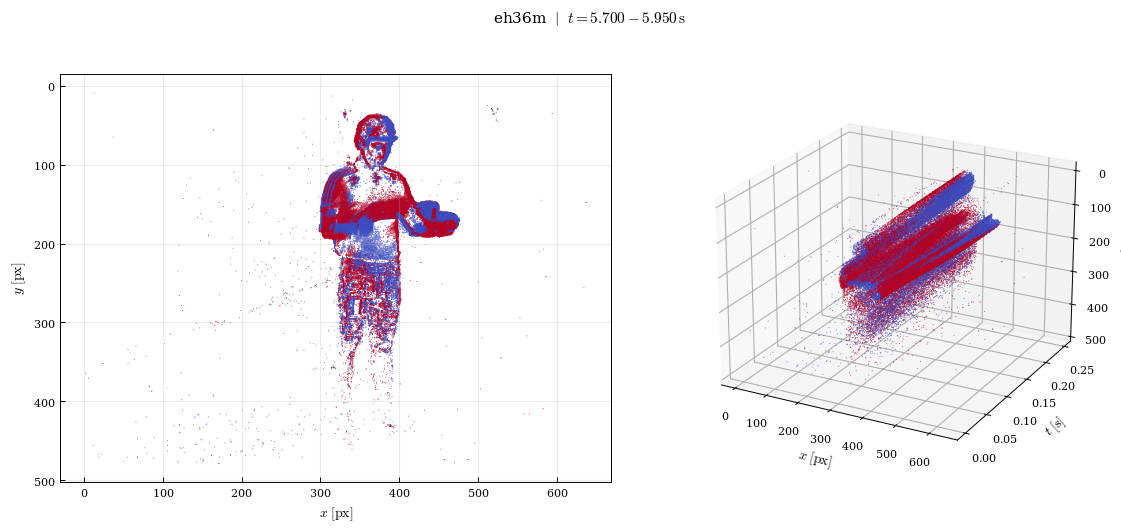

In [6]:
# ============================================================
# X-Y VIEW + INTERACTIVE 3D EVENT POINT CLOUD
# ============================================================

# Close old interactive figures
plt.close("all")


# ============================================================
# SELECT EVENTS TO DISPLAY
# ============================================================

n_events = len(event_t)

if n_events > MAX_DISPLAY_EVENTS:

    display_indices = np.linspace(
        0,
        n_events - 1,
        MAX_DISPLAY_EVENTS,
        dtype=int,
    )

    print(
        f"Displaying "
        f"{MAX_DISPLAY_EVENTS:,} / "
        f"{n_events:,} events"
    )

else:

    display_indices = np.arange(n_events)


x_plot = event_x[display_indices]
y_plot = event_y[display_indices]
t_plot = event_t[display_indices]
p_plot = event_p[display_indices]


# ============================================================
# FIGURE
# ============================================================

fig = plt.figure(
    figsize=(12, 5)
)


# ------------------------------------------------------------
# GLOBAL TITLE
# ------------------------------------------------------------

fig.suptitle(
    rf"{DATASET} $\;|\;$ "
    rf"$t = {START_TIME:.3f}"
    rf"-{START_TIME + DURATION:.3f}\,\mathrm{{s}}$",
    fontsize=11,
)


# ============================================================
# 1. X-Y VIEW
# ============================================================

ax_xy = fig.add_subplot(
    1,
    2,
    1,
)


ax_xy.scatter(
    x_plot,
    y_plot,

    c=p_plot,
    cmap="coolwarm",

    s=0.5,
    alpha=0.8,
    linewidths=0,
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax_xy.set_xlabel(
    r"$x\;[\mathrm{px}]$"
)

ax_xy.set_ylabel(
    r"$y\;[\mathrm{px}]$"
)

# ax_xy.set_title(
#     r"$x$-$y$"
# )


# ------------------------------------------------------------
# Image coordinates
# ------------------------------------------------------------

# y grows downwards in the image
ax_xy.invert_yaxis()


# Correct spatial aspect ratio
ax_xy.set_aspect(
    "equal",
    adjustable="box",
)


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax_xy.grid(
    True,
    alpha=0.25,
)


# ============================================================
# 2. INTERACTIVE 3D VIEW
# ============================================================

ax_3d = fig.add_subplot(
    1,
    2,
    2,
    projection="3d",
)


ax_3d.scatter(
    x_plot,
    t_plot,
    y_plot,

    c=p_plot,
    cmap="coolwarm",

    s=0.5,
    alpha=0.8,
    linewidths=0,
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax_3d.set_xlabel(
    r"$x\;[\mathrm{px}]$"
)

ax_3d.set_ylabel(
    r"$t\;[\mathrm{s}]$"
)

ax_3d.set_zlabel(
    r"$y\;[\mathrm{px}]$"
)

# ax_3d.set_title(
#     r"$x$-$t$-$y$"
# )


# ------------------------------------------------------------
# Coordinate convention
# ------------------------------------------------------------

# y grows downwards in the image
ax_3d.invert_zaxis()


# ------------------------------------------------------------
# Initial 3D camera
# ------------------------------------------------------------

ax_3d.view_init(
    elev=22,
    azim=-62,
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.show()

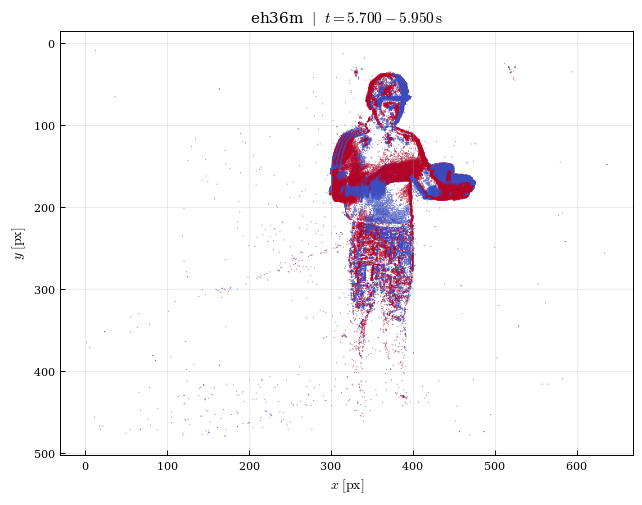

In [7]:
# ============================================================
# X-Y EVENT VIEW
# ============================================================

plt.close("all")

n_events = len(event_t)

if n_events > MAX_DISPLAY_EVENTS:
    display_indices = np.linspace(
        0,
        n_events - 1,
        MAX_DISPLAY_EVENTS,
        dtype=int,
    )

    print(
        f"Displaying "
        f"{MAX_DISPLAY_EVENTS:,} / "
        f"{n_events:,} events"
    )

else:
    display_indices = np.arange(n_events)


x_plot = event_x[display_indices]
y_plot = event_y[display_indices]
p_plot = event_p[display_indices]


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 5)
)


ax.scatter(
    x_plot,
    y_plot,
    c=p_plot,
    cmap="coolwarm",
    s=0.5,
    alpha=0.8,
    linewidths=0,
)


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_xlabel(
    r"$x\;[\mathrm{px}]$"
)

ax.set_ylabel(
    r"$y\;[\mathrm{px}]$"
)

# Image coordinates: y grows downwards
ax.invert_yaxis()

# Correct image aspect ratio
ax.set_aspect(
    "equal",
    adjustable="box",
)

ax.grid(
    True,
    alpha=0.25,
)


# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    rf"{DATASET} $\;|\;$ "
    rf"$t = {START_TIME:.3f}"
    rf"-{START_TIME + DURATION:.3f}\,\mathrm{{s}}$",
    fontsize=11,
)


plt.tight_layout()
plt.show()

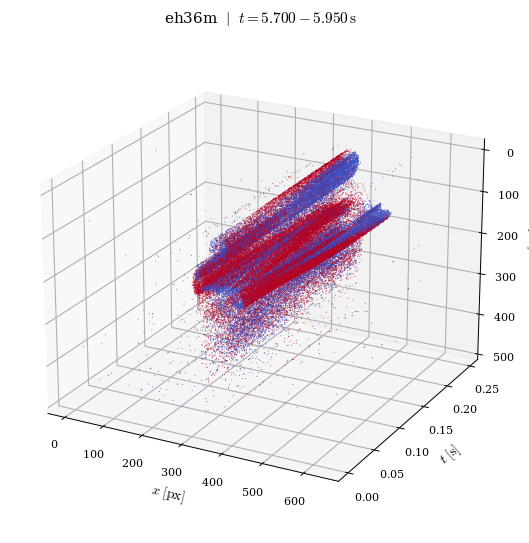

In [8]:
# ============================================================
# INTERACTIVE 3D EVENT POINT CLOUD
# ============================================================

plt.close("all")

n_events = len(event_t)

if n_events > MAX_DISPLAY_EVENTS:
    display_indices = np.linspace(
        0,
        n_events - 1,
        MAX_DISPLAY_EVENTS,
        dtype=int,
    )

    print(
        f"Displaying "
        f"{MAX_DISPLAY_EVENTS:,} / "
        f"{n_events:,} events"
    )

else:
    display_indices = np.arange(n_events)


x_plot = event_x[display_indices]
y_plot = event_y[display_indices]
t_plot = event_t[display_indices]
p_plot = event_p[display_indices]


# ============================================================
# FIGURE
# ============================================================

fig = plt.figure(
    figsize=(7, 5.5)
)

ax = fig.add_subplot(
    111,
    projection="3d",
)


ax.scatter(
    x_plot,
    t_plot,
    y_plot,
    c=p_plot,
    cmap="coolwarm",
    s=0.5,
    alpha=0.8,
    linewidths=0,
)


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_xlabel(
    r"$x\;[\mathrm{px}]$"
)

ax.set_ylabel(
    r"$t\;[\mathrm{s}]$"
)

ax.set_zlabel(
    r"$y\;[\mathrm{px}]$"
)

# Image coordinates: y grows downwards
ax.invert_zaxis()


# ------------------------------------------------------------
# Initial camera angle
# ------------------------------------------------------------

ax.view_init(
    elev=22,
    azim=-62,
)


# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    rf"{DATASET} $\;|\;$ "
    rf"$t = {START_TIME:.3f}"
    rf"-{START_TIME + DURATION:.3f}\,\mathrm{{s}}$",
    fontsize=11,
)


plt.tight_layout()
plt.show()